# dense와 sparse 비교

**이 노트북에서 할 일**

1. 같은 문서 12개와 질문 8개로 두 검색 방법의 재료를 만듭니다.
2. 질문 하나를 두 방법으로 재어 상위 세 문서를 나란히 봅니다.
3. 질문만 바꿔 두 방법의 1위가 어떻게 달라지는지 봅니다.
4. 질문 여덟 개의 정답 자리와 재현율을 한 표에서 견줍니다.

**준비물** — 프로젝트 폴더의 `.env`에 `OPENAI_API_KEY`가 있어야 합니다.
임베딩 요청은 문서 1번과 질문 8번으로 모두 아홉 번입니다.
예상 비용은 미화 0.01달러 아래이고 답을 쓰는 모델은 부르지 않습니다.
실행 시간은 1분 안팎이고 첫 셀의 설치가 가장 오래 걸립니다.

**데이터** — 두 파일 모두 실습 묶음에 들어 있습니다.

- 문서 `labs/part3/ch12-retrieval-tuning/data/core-documents.json`(12개)
- 질문 `labs/part3/ch12-retrieval-tuning/data/core-queries.json`(8개)

**강의와 실습 범위** — 강의 시간에는 3~5절과 6~7절, 9절을 읽습니다.
두 방법의 재료를 만들고 가져온 순위 함수 두 개의 인자를 확인하는 자리입니다.
6~7절은 실행 1과 값 바꿔 보기이고 9절은 질문 여덟 개 비교입니다.
1~2절과 8절은 함께 실행하고 실습 시간에 다시 읽습니다.

**기준 버전** — 첫 셀에서 다섯 패키지를 고정한 판으로 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch12-retrieval-tuning`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

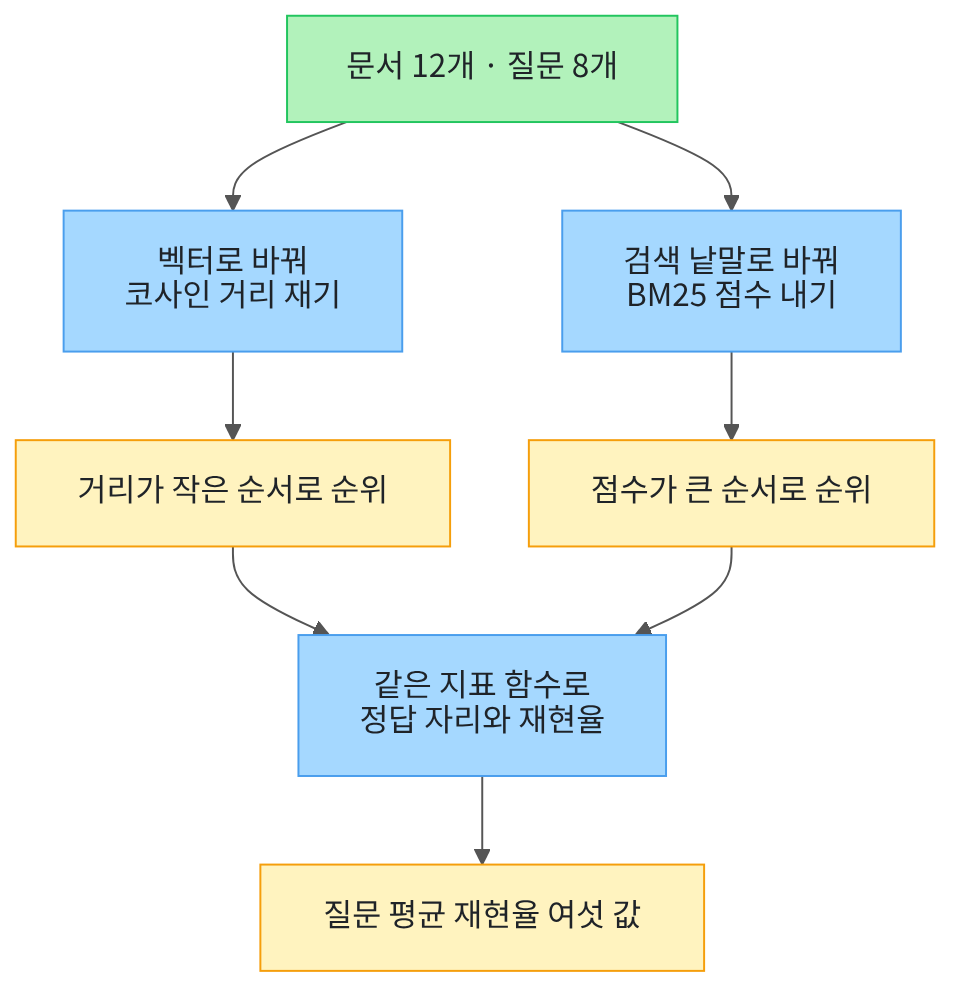

맨 위 초록 상자가 두 방법이 함께 보는 자료입니다.
거기서 두 갈래로 갈리고 파란 상자는 우리가 정한 처리입니다.
두 갈래의 노란 상자는 값의 방향이 서로 반대입니다.
아래에서 두 순위가 같은 지표 함수로 모입니다.
맨 아래 노란 상자가 이 노트북의 마지막 출력입니다.

## 1. 준비

첫 셀은 패키지 다섯 개를 설치하고 설치된 버전을 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain-openai==1.6.1" "python-dotenv==1.2.3" "kiwipiepy==0.23.2" "rank-bm25==0.2.2" "numpy==2.5.3"
from importlib.metadata import version

print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("kiwipiepy:", version("kiwipiepy"))
print("rank-bm25:", version("rank-bm25"))
print("numpy:", version("numpy"))

Note: you may need to restart the kernel to use updated packages.
langchain-openai: 1.6.1
python-dotenv: 1.2.3
kiwipiepy: 0.23.2
rank-bm25: 0.2.2
numpy: 2.5.3


**결과 읽기** — 설치가 끝나면 `langchain-openai: 1.6.1`과 `kiwipiepy: 0.23.2`가 보입니다.
마지막 줄 `numpy: 2.5.3`은 도구 파일이 벡터 계산에 쓰는 패키지입니다. 다섯 줄이 모두 보이면 다음 셀로 넘어갑니다.
01~03절은 앞 두 패키지를 썼고 04절은 셋째와 넷째 패키지를 썼습니다.

다음 셀은 이 절에서 쓸 이름 네 개를 불러옵니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.

이 노트북은 01·04절 함수 네 개와 Ch 11 지표 함수 네 개를 가져옵니다.
01절 `rank_by_distance()`, 04절 `kiwi_terms()`·`count_docs_with()`·`rank_by_bm25()`입니다.
Ch 11 함수는 `unique_doc_ids()`·`find_gold_rank()`·`recall_at()`·`mean_score()`입니다.
인자 모양이 앞 절 판과 다른 함수는 쓰는 자리에서 설명합니다.

In [2]:
# 자료 읽기·임베딩·형태소 분석·낱말 점수에 쓸 이름을 불러옵니다
import json

from kiwipiepy import Kiwi
from langchain_openai import OpenAIEmbeddings
from rank_bm25 import BM25Okapi
# 01·04절과 Ch 11 01·02절 함수 여덟 개를 도구 파일에서 가져옵니다
from rag_tools import count_docs_with, find_gold_rank, kiwi_terms, mean_score
from rag_tools import rank_by_bm25, rank_by_distance, recall_at, unique_doc_ids

print("불러온 이름:", "json", "Kiwi", "OpenAIEmbeddings", "BM25Okapi")

불러온 이름: json Kiwi OpenAIEmbeddings BM25Okapi


**결과 읽기** — 출력 줄은 `불러온 이름:` 뒤에 이름 네 개가 붙은 한 줄입니다.
이름 `OpenAIEmbeddings`는 글을 벡터로 바꾸는 도구입니다.
이름 `Kiwi`와 `BM25Okapi`는 04절에서 쓴 두 도구입니다.
도구 파일에서 가져온 함수 여덟 개는 출력하지 않습니다.

다음 셀은 API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True` 하나입니다.
키 값은 출력하지 않습니다.
04절은 임베딩을 쓰지 않아 이 셀이 없었습니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다. 01~04절과 같은 코드입니다.

In [4]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part3/ch12-retrieval-tuning/data"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.

다음 셀은 01~04절이 쓴 문서 파일과 질문 파일을 그대로 읽습니다.

In [5]:
# 01~04절과 같은 문서 파일과 질문 파일을 불러옵니다
data_path = root_path + "/labs/part3/ch12-retrieval-tuning/data"
with open(data_path + "/core-documents.json", encoding="utf-8") as file:
    docs = json.loads(file.read())
with open(data_path + "/core-queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
print("문서 수:", len(docs))
print("질문 수:", len(queries))

문서 수: 12
질문 수: 8


**결과 읽기** — `문서 수: 12`와 `질문 수: 8`이 보입니다.
01~04절과 같은 교육용 자료입니다.
같은 자료를 써야 두 방법의 값을 나란히 놓을 수 있습니다.

## 2. 이 절에서 쓸 값 정하기

값 다섯 개를 먼저 정합니다.
이름 `top_all`은 정답 자리를 셀 때 재는 문서 수입니다.
문서 12개를 끝까지 재면 정답 자리가 1에서 12 사이로 나옵니다.
남길 품사 표시 아홉 가지는 04절에서 정한 목록과 같습니다.

In [6]:
# 이 절에서 되풀이해 쓸 값과 견줄 방법 이름을 정합니다
top_three = 3
top_all = 12
cutoff_values = [1, 2, 3]
keep_tags = ["NNG", "NNP", "NNB", "NR", "VV", "VA", "MAG", "SN", "SL"]
method_names = ["벡터 거리", "낱말 겹침"]
print("나란히 볼 상위 문서 수:", top_three)
print("자리를 셀 때 재는 문서 수:", top_all)
print("자르는 자리 세 가지:", cutoff_values)
print("남길 품사 표시:", keep_tags)
print("견줄 방법 두 가지:", method_names)

나란히 볼 상위 문서 수: 3
자리를 셀 때 재는 문서 수: 12
자르는 자리 세 가지: [1, 2, 3]
남길 품사 표시: ['NNG', 'NNP', 'NNB', 'NR', 'VV', 'VA', 'MAG', 'SN', 'SL']
견줄 방법 두 가지: ['벡터 거리', '낱말 겹침']


**결과 읽기** — `나란히 볼 상위 문서 수: 3`과 `자리를 셀 때 재는 문서 수: 12`가 보입니다.
출력 줄 `자르는 자리 세 가지: [1, 2, 3]`은 01~04절과 같은 값입니다.
`견줄 방법 두 가지: ['벡터 거리', '낱말 겹침']` 줄의 두 이름으로 뒤에서 기록을 나눕니다.
라벨 줄 `남길 품사 표시:` 뒤에는 이름 아홉 개가 있습니다.

## 3. 두 방법이 볼 재료 만들기

두 방법은 같은 글에서 서로 다른 재료를 만듭니다.
먼저 문서 12개의 제목과 본문을 이어 붙여 글 열두 개로 만듭니다.
이 글이 벡터로도 바뀌고 검색 낱말로도 바뀝니다.

In [7]:
# 문서 12개의 제목과 본문을 이어 붙이고 문서 ID 목록도 만듭니다(01~04절과 같은 모양)
doc_texts = []
doc_ids = []
for doc in docs:
    doc_texts.append(doc["title"] + " " + doc["text"])
    doc_ids.append(doc["doc_id"])
print("이어 붙인 글 수:", len(doc_texts))
print("첫 문서 글:", doc_texts[0])
print("문서 ID 목록:")
print(doc_ids)

이어 붙인 글 수: 12
첫 문서 글: 도서 대출 기간 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.
문서 ID 목록:
['LIB-001', 'LIB-002', 'LIB-003', 'LIB-004', 'FAC-001', 'FAC-002', 'FAC-003', 'FAC-004', 'ACC-001', 'ACC-002', 'ACC-003', 'ACC-004']


**결과 읽기** — `이어 붙인 글 수: 12`가 보입니다.
출력 줄 `첫 문서 글:` 뒤에는 제목 `도서 대출 기간`과 본문이 이어져 있습니다.
라벨 줄 `문서 ID 목록:` 아래 줄에 `LIB-001`부터 열두 개가 있습니다.
이 순서가 뒤에서 순위를 만들 때 문서를 가리키는 차례입니다.

다음 셀은 벡터 거리 쪽 재료를 만듭니다.
01~03절과 같은 모델과 같은 숫자 개수를 씁니다.

In [8]:
# 01~03절과 같은 모델로 문서 12개와 질문 8개를 벡터로 바꿉니다(임베딩 요청 9번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
doc_vectors = embedding_model.embed_documents(doc_texts)
query_vectors = []
for query in queries:
    query_vectors.append(embedding_model.embed_query(query["question"]))
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 벡터 수:", len(doc_vectors))
print("질문 벡터 수:", len(query_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 벡터 수: 12
질문 벡터 수: 8


**결과 읽기** — `벡터의 숫자 개수 설정: 256`과 `문서 벡터 수: 12`가 보입니다.
출력 줄 `질문 벡터 수: 8`까지 나오면 임베딩 요청 아홉 번이 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

다음 셀은 낱말 겹침 쪽 재료를 만듭니다.
검색 낱말은 준비 셀에서 가져온 04절 함수 `kiwi_terms()`로 만듭니다.
도구 파일 판은 04절 판이 바로 읽던 분석기와 남길 품사 표시를 인자로 받습니다.
분석기를 만드는 줄 `kiwi = Kiwi()`는 1초 안팎 걸립니다.

In [9]:
# 04절과 같은 형태소 분석기로 문서 12개의 검색 낱말 목록을 만들고 BM25 모델을 만듭니다
kiwi = Kiwi()
kiwi_corpus = []
for text in doc_texts:
    kiwi_corpus.append(kiwi_terms(kiwi, text, keep_tags))
bm25_model = BM25Okapi(kiwi_corpus)
print("검색 낱말 목록 수:", len(kiwi_corpus))
print("BM25 모델이 본 문서 수:", bm25_model.corpus_size)
print("문서 하나의 평균 검색 낱말 수:", round(bm25_model.avgdl, 2))

검색 낱말 목록 수: 12
BM25 모델이 본 문서 수: 12
문서 하나의 평균 검색 낱말 수: 15.33


**결과 읽기** — `검색 낱말 목록 수: 12`와 `BM25 모델이 본 문서 수: 12`가 보입니다.
출력 줄 `문서 하나의 평균 검색 낱말 수: 15.33`은 04절과 같은 값입니다.
같은 글에서 같은 함수로 만든 목록이라 04절 색인과 같습니다.

## 4. 벡터 거리로 순위 만들기

벡터 거리 쪽 순위는 준비 셀에서 가져온 `rank_by_distance()`가 만듭니다.
질문 벡터를 문서 벡터 모두와 01절 코사인 거리로 재고, 거리가 작은 순서로 앞 몇 개를 남깁니다.
인자는 질문 벡터, 문서 벡터 목록, 문서 ID 목록, 남길 개수 네 가지입니다. 값 칸 이름은 `거리`입니다.
03절에서 범주 하나에 쓴 함수와 같은 판입니다.

## 5. 낱말 겹침으로 순위 만들기

낱말 겹침 쪽 순위는 04절 함수 `rank_by_bm25()`를 가져와 만듭니다.
도구 파일 판은 모델 하나와 질문의 검색 낱말 목록, 문서 ID 목록, 남길 개수를 받습니다.
04절 판은 정책 이름과 질문 글을 받아 함수 안에서 검색 낱말을 만들었습니다.
점수는 클수록 관련 있어 점수에 음수를 붙여 `sorted()`로 정렬하는 방법은 04절과 같습니다.

값 칸 이름은 `점수`입니다. 앞 함수의 `거리`와 뜻이 반대라 이름을 갈랐습니다.
다음 셀은 순위 목록을 표 모양으로 출력하는 함수입니다.
값 칸 이름을 인자로 받아 두 방법에 모두 씁니다.

In [10]:
# 순위 목록을 순위·문서 ID·값 세 칸으로 출력합니다(값 칸 이름을 인자로 받습니다)
def print_ranked(hit_list, value_name):
    print("순위 | 문서 ID |", value_name)
    for rank_number in range(len(hit_list)):
        row = hit_list[rank_number]
        print(rank_number + 1, "|", row["doc_id"], "|", row[value_name])

**결과 읽기** — 정의 셀이라 출력이 없습니다.

## 6. 실행 1 — 같은 질문을 두 방법으로

첫 질문을 두 방법으로 재어 상위 세 문서를 나란히 봅니다.
실행 전에 예상해 봅니다.
질문이 `책을 빌릴 수 있는 기간은 며칠인가요?`이므로 대출 기간 문서가 앞에 올 것입니다.

In [11]:
# 실행 1: 첫 질문을 두 방법으로 재어 상위 세 문서를 나란히 봅니다
first_query = queries[0]
first_terms = kiwi_terms(kiwi, first_query["question"], keep_tags)
first_distance_hits = rank_by_distance(query_vectors[0], doc_vectors, doc_ids, top_three)
first_score_hits = rank_by_bm25(bm25_model, first_terms, doc_ids, top_three)
print("고른 질문:", first_query["qid"], "|", first_query["question"])
print("그 질문의 정답 문서 ID:", first_query["gold_doc_id"])
print("질문의 갈래:", first_query["kind"])
print("질문의 검색 낱말:", first_terms)
print_ranked(first_distance_hits, "거리")
print_ranked(first_score_hits, "점수")

고른 질문: C01 | 책을 빌릴 수 있는 기간은 며칠인가요?
그 질문의 정답 문서 ID: LIB-001
질문의 갈래: semantic
질문의 검색 낱말: ['책', '빌리', '수', '있', '기간', '며칠']
순위 | 문서 ID | 거리
1 | LIB-004 | 0.43
2 | LIB-001 | 0.56
3 | LIB-003 | 0.62
순위 | 문서 ID | 점수
1 | LIB-004 | 3.37
2 | LIB-003 | 2.59
3 | LIB-001 | 2.01


**결과 읽기** — 라벨 줄 `순위 | 문서 ID | 거리` 아래 첫 줄은 `1 | LIB-004 | 0.43`입니다.
정답 문서 `LIB-001`은 `2 | LIB-001 | 0.56` 줄에 있습니다.
라벨 줄 `순위 | 문서 ID | 점수` 아래 첫 줄은 `1 | LIB-004 | 3.37`이고 정답 문서는 `3 | LIB-001 | 2.01` 줄입니다.
두 방법의 상위 세 문서는 같은 세 건이고 순서만 다릅니다.
정답 문서가 1위인 방법은 없고 자리는 벡터 거리 2와 낱말 겹침 3입니다.

두 방법 모두 1위로 `LIB-004`를 골랐습니다.
그 문서는 전자책 대출 기간을 다루고 정답 문서는 일반 도서 대출 기간을 다룹니다.
출력 줄 `질문의 갈래: semantic`은 질문 파일이 「말을 바꾼 질문」으로 적어 둔 표시입니다.

## 7. 값 바꿔 보기 — 질문 하나만 바꾸기

바꿀 값은 질문 하나입니다.
문서와 재는 방법, 상위 문서 수는 그대로 둡니다.
실행 전에 예상해 봅니다. 두 방법이 같은 문서를 1위로 고를 것입니다.

In [12]:
# 값 바꿔 보기: 질문 하나만 바꿔 같은 두 방법으로 다시 잽니다
second_query = queries[1]
second_terms = kiwi_terms(kiwi, second_query["question"], keep_tags)
second_distance_hits = rank_by_distance(query_vectors[1], doc_vectors, doc_ids, top_three)
second_score_hits = rank_by_bm25(bm25_model, second_terms, doc_ids, top_three)
print("고른 질문:", second_query["qid"], "|", second_query["question"])
print("그 질문의 정답 문서 ID:", second_query["gold_doc_id"])
print("질문의 갈래:", second_query["kind"])
print("질문의 검색 낱말:", second_terms)
print_ranked(second_distance_hits, "거리")
print_ranked(second_score_hits, "점수")

고른 질문: C02 | 책을 늦게 반납하면 돈을 내나요?
그 질문의 정답 문서 ID: LIB-002
질문의 갈래: semantic
질문의 검색 낱말: ['책', '늦', '반납', '돈', '내']
순위 | 문서 ID | 거리
1 | LIB-003 | 0.56
2 | LIB-004 | 0.58
3 | LIB-001 | 0.65
순위 | 문서 ID | 점수
1 | LIB-002 | 2.26
2 | LIB-003 | 2.11
3 | LIB-004 | 1.45


**결과 읽기** — 예상과 달랐습니다.
라벨 줄 `순위 | 문서 ID | 거리` 아래 세 줄에 정답 문서 `LIB-002`가 없습니다.
첫 줄은 `1 | LIB-003 | 0.56`입니다.
라벨 줄 `순위 | 문서 ID | 점수` 아래 첫 줄은 `1 | LIB-002 | 2.26`으로 정답 문서입니다.
이 질문의 갈래도 `semantic`인데 앞 질문과 이긴 방법이 다릅니다.

다음 셀은 낱말 겹침 쪽이 정답 문서를 1위로 고른 자리를 찾습니다.
질문의 검색 낱말과 정답 문서의 검색 낱말을 견줍니다.

In [13]:
# 값 바꿔 보기 질문과 그 정답 문서에 함께 있는 검색 낱말을 찾습니다
second_gold_terms = []
for i in range(len(doc_ids)):
    if doc_ids[i] == second_query["gold_doc_id"]:
        second_gold_terms = kiwi_corpus[i]
        break
shared_terms = []
for term in second_terms:
    if term in second_gold_terms:
        shared_terms.append(term)
print("정답 문서의 검색 낱말:", second_gold_terms)
print("질문과 정답 문서에 함께 있는 낱말:", shared_terms)

정답 문서의 검색 낱말: ['연체', '대출', '제한', '반납', '예정일', '넘기', '연체', '날짜', '대출', '제한', '연체료', '부과']
질문과 정답 문서에 함께 있는 낱말: ['반납']


**결과 읽기** — 출력 줄 `정답 문서의 검색 낱말:` 뒤에 낱말 열두 개가 보입니다.
출력 줄 `질문과 정답 문서에 함께 있는 낱말: ['반납']`에서 겹치는 낱말이 하나입니다.
낱말 `돈`과 `연체료`는 뜻이 이어지지만 글자가 달라 겹치지 않습니다.

다음 셀은 그 낱말이 문서 몇 건에 있는지 셉니다.
04절 함수 `count_docs_with()`를 가져와 씁니다. 도구 파일 판은 검색 낱말 목록의 목록을 첫 인자로 받습니다.

In [14]:
# 함께 있는 낱말이 문서 12개 가운데 몇 건에 있는지 04절 함수로 셉니다
print("함께 있는 낱말 | 그 낱말이 있는 문서 수")
for term in shared_terms:
    print(term, "|", count_docs_with(kiwi_corpus, term))

함께 있는 낱말 | 그 낱말이 있는 문서 수
반납 | 1


**결과 읽기** — 라벨 줄 아래 한 줄 `반납 | 1`이 보입니다.
낱말 `반납`은 문서 열두 건 가운데 한 건에만 있습니다.
04절에서 본 대로 드문 낱말은 그 문서를 가리키는 힘이 셉니다.
벡터 거리 쪽이 왜 이 문서를 뒤로 두었는지는 모델 안을 볼 수 없어 적지 않습니다.

## 8. 질문 여덟 개를 잴 함수 준비

질문 두 개로는 두 방법의 차이를 말할 수 없습니다.
지표 함수 네 개는 준비 셀에서 가져온 Ch 11 함수를 그대로 씁니다.
함수 `unique_doc_ids()`가 보는 키는 `doc_id` 하나여서 두 방법의 순위 목록에 모두 씁니다.

다음 셀은 순위 목록 하나를 받아 기록 한 줄을 만듭니다.
값 칸을 빼고 자리와 재현율만 담아 두 방법을 한 표에 둡니다.

In [15]:
# 순위 목록 하나를 받아 정답 자리와 자르는 자리별 재현율을 기록 한 줄로 만듭니다
def score_one(query_index, method_name, hit_list):
    query = queries[query_index]
    gold_doc_ids = [query["gold_doc_id"]]
    found_ids = unique_doc_ids(hit_list)
    row = {"방법": method_name, "질문": query["qid"], "갈래": query["kind"]}
    row["정답 자리"] = find_gold_rank(found_ids, gold_doc_ids)
    for cutoff in cutoff_values:
        row["자리 " + str(cutoff)] = recall_at(found_ids, gold_doc_ids, cutoff)
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
인자 `hit_list`를 밖에서 받으므로 이 함수는 어느 방법인지 보지 않습니다.

## 9. 두 방법의 재현율 견주기

질문 여덟 개를 두 방법으로 모두 잽니다.
벡터와 BM25 모델을 미리 만들어 두었으므로 요청은 더 보내지 않습니다.

In [16]:
# 질문 여덟 개를 두 방법으로 모두 재어 기록 줄을 담습니다(임베딩 요청은 더 보내지 않습니다)
score_rows = []
for method_name in method_names:
    for query_index in range(len(queries)):
        # 두 방법이 갈리는 곳은 이 조건 하나입니다
        if method_name == method_names[0]:
            hit_list = rank_by_distance(query_vectors[query_index], doc_vectors, doc_ids, top_all)
        else:
            question_terms = kiwi_terms(kiwi, queries[query_index]["question"], keep_tags)
            hit_list = rank_by_bm25(bm25_model, question_terms, doc_ids, top_all)
        score_rows.append(score_one(query_index, method_name, hit_list))
print("담은 기록 줄 수:", len(score_rows))

담은 기록 줄 수: 16


**결과 읽기** — `담은 기록 줄 수: 16`이 보입니다. 질문 여덟 개에 방법 두 가지를 곱한 수입니다.

다음 셀은 담은 줄을 표로 출력합니다.

In [17]:
# 방법·질문·갈래·정답 자리·자리 1·자리 3을 라벨 줄 아래에 차례로 출력합니다
print("방법 | 질문 | 갈래 | 정답 자리 | 자리 1 재현율 | 자리 3 재현율")
for row in score_rows:
    print(row["방법"], "|", row["질문"], "|", row["갈래"], "|", row["정답 자리"], "|", row["자리 1"], "|", row["자리 3"])

방법 | 질문 | 갈래 | 정답 자리 | 자리 1 재현율 | 자리 3 재현율
벡터 거리 | C01 | semantic | 2 | 0.0 | 1.0
벡터 거리 | C02 | semantic | 7 | 0.0 | 0.0
벡터 거리 | C03 | keyword | 1 | 1.0 | 1.0
벡터 거리 | C04 | keyword | 1 | 1.0 | 1.0
벡터 거리 | C05 | semantic | 1 | 1.0 | 1.0
벡터 거리 | C06 | semantic | 1 | 1.0 | 1.0
벡터 거리 | C07 | keyword | 1 | 1.0 | 1.0
벡터 거리 | C08 | semantic | 1 | 1.0 | 1.0
낱말 겹침 | C01 | semantic | 3 | 0.0 | 1.0
낱말 겹침 | C02 | semantic | 1 | 1.0 | 1.0
낱말 겹침 | C03 | keyword | 1 | 1.0 | 1.0
낱말 겹침 | C04 | keyword | 1 | 1.0 | 1.0
낱말 겹침 | C05 | semantic | 1 | 1.0 | 1.0
낱말 겹침 | C06 | semantic | 1 | 1.0 | 1.0
낱말 겹침 | C07 | keyword | 1 | 1.0 | 1.0
낱말 겹침 | C08 | semantic | 1 | 1.0 | 1.0


**결과 읽기** — 라벨 줄 아래 앞 여덟 줄이 벡터 거리입니다.
줄 `벡터 거리 | C02 | semantic | 7 | 0.0 | 0.0`에서 정답 자리가 7입니다.
자리 3 재현율이 `0.0`이므로 상위 세 자리 안에 정답 문서가 없었습니다.
뒤 여덟 줄은 낱말 겹침이고 `낱말 겹침 | C02 | semantic | 1 | 1.0 | 1.0` 줄이 같은 질문입니다.
줄 `낱말 겹침 | C01 | semantic | 3 | 0.0 | 1.0`은 정답 문서가 셋째 자리였던 질문입니다.

벡터 거리 쪽 여덟 줄의 정답 자리는 01절 표의 값과 같습니다.
낱말 겹침 쪽 여덟 줄의 정답 자리는 04절 표의 값과 같습니다.
03·04절 표는 상위 3개만 담아 자리가 0에서 3까지였습니다.
이 표는 문서 12개를 끝까지 재어 자리가 1에서 12까지 나옵니다.

다음 셀은 자르는 자리마다 질문 평균 재현율을 견줍니다.

In [18]:
# 두 방법의 질문 평균 재현율을 자르는 자리마다 견줍니다
print("방법 | 자르는 자리 | 질문 평균 재현율")
for method_name in method_names:
    picked = []
    for row in score_rows:
        if row["방법"] == method_name:
            picked.append(row)
    for cutoff in cutoff_values:
        scores = []
        for row in picked:
            scores.append(row["자리 " + str(cutoff)])
        print(method_name, "|", cutoff, "|", mean_score(scores))

방법 | 자르는 자리 | 질문 평균 재현율
벡터 거리 | 1 | 0.75
벡터 거리 | 2 | 0.875
벡터 거리 | 3 | 0.875
낱말 겹침 | 1 | 0.875
낱말 겹침 | 2 | 0.875
낱말 겹침 | 3 | 1.0


**결과 읽기** — 라벨 줄 아래 여섯 줄이 나옵니다.
벡터 거리는 자리 1에서 `0.75`이고 자리 3에서 `0.875`입니다.
낱말 겹침은 자리 1에서 `0.875`이고 자리 3에서 `1.0`입니다.
앞 세 줄은 01절 질문 평균과 같고 뒤 세 줄은 04절 질문 평균과 같습니다.

다음 셀은 정답 자리가 다른 질문만 골라 봅니다.

In [19]:
# 두 방법의 정답 자리가 다른 질문만 골라 라벨 줄 아래에 출력합니다
print("질문 | 벡터 거리 자리 | 낱말 겹침 자리")
for query_index in range(len(queries)):
    qid = queries[query_index]["qid"]
    places = []
    for row in score_rows:
        if row["질문"] == qid:
            places.append(row["정답 자리"])
    if places[0] != places[1]:
        print(qid, "|", places[0], "|", places[1])

질문 | 벡터 거리 자리 | 낱말 겹침 자리
C01 | 2 | 3
C02 | 7 | 1


**결과 읽기** — 라벨 줄 아래 두 줄 `C01 | 2 | 3`과 `C02 | 7 | 1`이 보입니다.
질문 `C01`에서는 벡터 거리 쪽 자리가 앞이고 `C02`에서는 낱말 겹침 쪽 자리가 앞입니다.
두 질문 모두 갈래가 `semantic`이라 갈래로 방법을 고를 수 없습니다.
나머지 여섯 질문은 두 방법의 정답 자리가 같았습니다.

## 정리

1. 같은 문서 12개와 질문 8개를 두 방법에 넣어 순위를 나란히 놓았습니다.
2. 질문 `C01`은 벡터 거리 쪽 자리가 2이고 낱말 겹침 쪽이 3이었습니다.
3. 질문 `C02`는 벡터 거리 쪽 자리가 7이고 낱말 겹침 쪽이 1이었습니다.

06절에서는 두 순위를 하나로 합칩니다.
점수를 더하지 않고 자리 번호만 써서 합치는 방법을 씁니다.